In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_fashion_mnist

from src.preprocessing import (
    flatten_images,
    scale_pixels,
    create_validation_split,
    fit_pca,
    transform_pca
)

from src.models import create_svm

In [2]:
X_train, y_train, X_test, y_test = load_fashion_mnist()

X_train_flat = flatten_images(X_train)
X_test_flat = flatten_images(X_test)

X_train_scaled = scale_pixels(X_train_flat)
X_test_scaled = scale_pixels(X_test_flat)

X_fit, X_val, y_fit, y_val = create_validation_split(
    X_train_scaled,
    y_train
)

PCA_COMPONENTS = 187

pca, X_fit_pca = fit_pca(
    X_fit,
    PCA_COMPONENTS
)

X_test_pca = transform_pca(
    pca,
    X_test_scaled
)

In [3]:
best_model = create_svm(
    C=10,
    gamma="scale"
)

best_model.fit(
    X_fit_pca,
    y_fit
)

y_test_pred = best_model.predict(
    X_test_pca
)
from sklearn.metrics import accuracy_score

print(
    "Test accuracy:",
    accuracy_score(y_test, y_test_pred)
)

Test accuracy: 0.8991


In [4]:
from sklearn.metrics import classification_report

CLASS_NAMES = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

report = classification_report(
    y_test,
    y_test_pred,
    target_names=CLASS_NAMES,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

report_df

,precision,recall,f1-score,support
T-shirt/top,0.833984,0.8540,0.843874,1000.0000
Trouser,0.988832,0.9740,0.981360,1000.0000
Pullover,0.808325,0.8350,0.821446,1000.0000
Dress,0.897817,0.9050,0.901394,1000.0000
Coat,0.829960,0.8200,0.824950,1000.0000
Sandal,0.982828,0.9730,0.977889,1000.0000
Shirt,0.746098,0.7170,0.731260,1000.0000
Sneaker,0.948343,0.9730,0.960513,1000.0000
Bag,0.980962,0.9790,0.979980,1000.0000
Ankle boot,0.973658,0.9610,0.967287,1000.0000


In [5]:
report_df.to_csv(
    "../results/classification_report.csv"
)

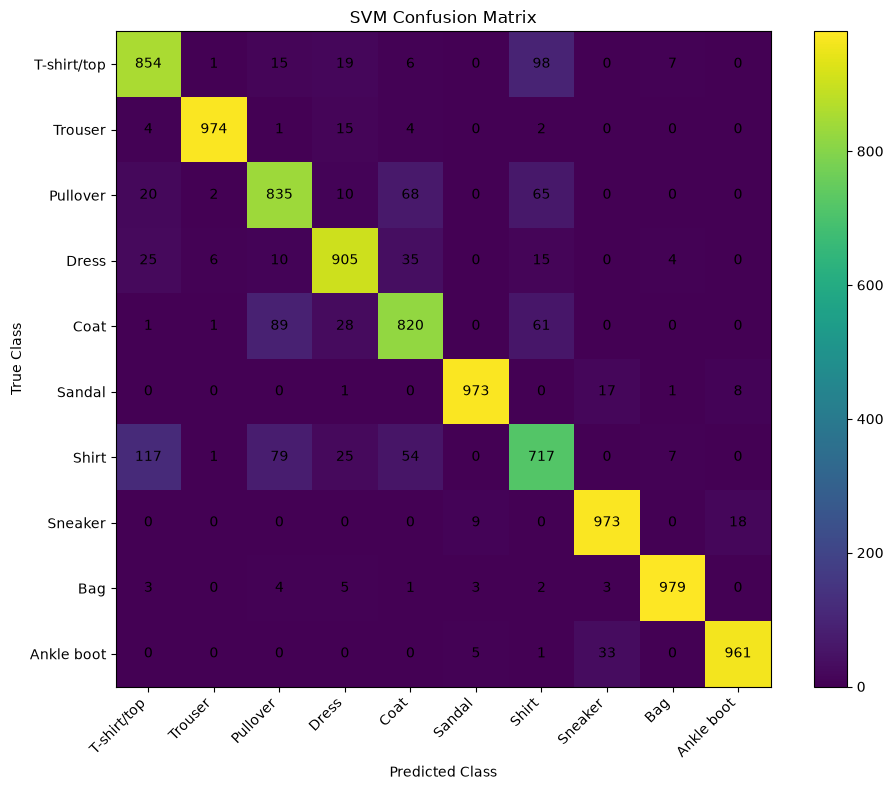

In [6]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_test_pred
)
fig, ax = plt.subplots(figsize=(10, 8))

image = ax.imshow(cm)

ax.set_xticks(range(10))
ax.set_yticks(range(10))

ax.set_xticklabels(
    CLASS_NAMES,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(CLASS_NAMES)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("True Class")
ax.set_title("SVM Confusion Matrix")

for i in range(10):
    for j in range(10):
        ax.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

fig.colorbar(image)

plt.tight_layout()

plt.savefig(
    "../results/figures/svm_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
cm_errors = cm.copy()

np.fill_diagonal(
    cm_errors,
    0
)

confusions = []

for true_class in range(10):
    for predicted_class in range(10):

        count = cm_errors[
            true_class,
            predicted_class
        ]

        if count > 0:
            confusions.append({
                "true_class": CLASS_NAMES[true_class],
                "predicted_class": CLASS_NAMES[predicted_class],
                "count": count
            })

confusion_df = pd.DataFrame(confusions)

confusion_df = confusion_df.sort_values(
    "count",
    ascending=False
)

confusion_df.head(15)

,true_class,predicted_class,count
31,Shirt,T-shirt/top,117
4,T-shirt/top,Shirt,98
24,Coat,Pullover,89
33,Shirt,Pullover,79
14,Pullover,Coat,68
15,Pullover,Shirt,65
26,Coat,Shirt,61
35,Shirt,Coat,54
19,Dress,Coat,35
48,Ankle boot,Sneaker,33


## Confusion Analysis

The RBF SVM achieved an overall test accuracy of **89.91%** and a
macro-F1 score of approximately **89.90%**. However, the per-class
results show that classification difficulty varies substantially
between clothing categories.

The most difficult class was **Shirt**, with a precision of **74.61%**,
recall of **71.70%**, and F1-score of **73.13%**. The largest individual
confusion occurred when **117 true Shirt images were classified as
T-shirt/top**. In the opposite direction, **98 T-shirt/top images were
classified as Shirt**.

Substantial confusion was also observed among the other upper-body
clothing categories:

- **89 Coat images** were classified as Pullover.
- **79 Shirt images** were classified as Pullover.
- **68 Pullover images** were classified as Coat.
- **65 Pullover images** were classified as Shirt.
- **61 Coat images** were classified as Shirt.
- **54 Shirt images** were classified as Coat.

These errors indicate a concentrated confusion group consisting of
**T-shirt/top, Pullover, Coat, and Shirt**. This is consistent with
their similar low-resolution silhouettes. The classifier ultimately
operates on information derived from 28×28 grayscale pixel
intensities, so visually similar upper-body garments can produce
similar feature representations. The representation does not
explicitly describe semantic properties such as fabric texture,
drape, garment construction, or sleeve characteristics.

In contrast, several visually distinctive classes were classified
very reliably. **Trouser, Sandal, Bag, Sneaker, and Ankle boot**
all achieved substantially stronger per-class results. Bag achieved
an F1-score of approximately **98.00%**, Trouser **98.14%**, Sandal
**97.79%**, Ankle boot **96.73%**, and Sneaker **96.05%**.

A smaller footwear confusion is nevertheless visible: **33 Ankle boot
images were classified as Sneaker**.

Overall, the confusion matrix shows that the model's errors are not
distributed uniformly across the ten classes. Most errors are
concentrated among structurally similar upper-body garments, with
**Shirt representing the principal weakness of the classifier**.
This supports the initial EDA hypothesis that visually similar
upper-body classes would be more difficult to separate than
distinctive categories such as trousers, bags, and footwear.

In [8]:
misclassified_indices = np.where(
    y_test != y_test_pred
)[0]

print(
    "Total misclassified:",
    len(misclassified_indices)
)

Total misclassified: 1009


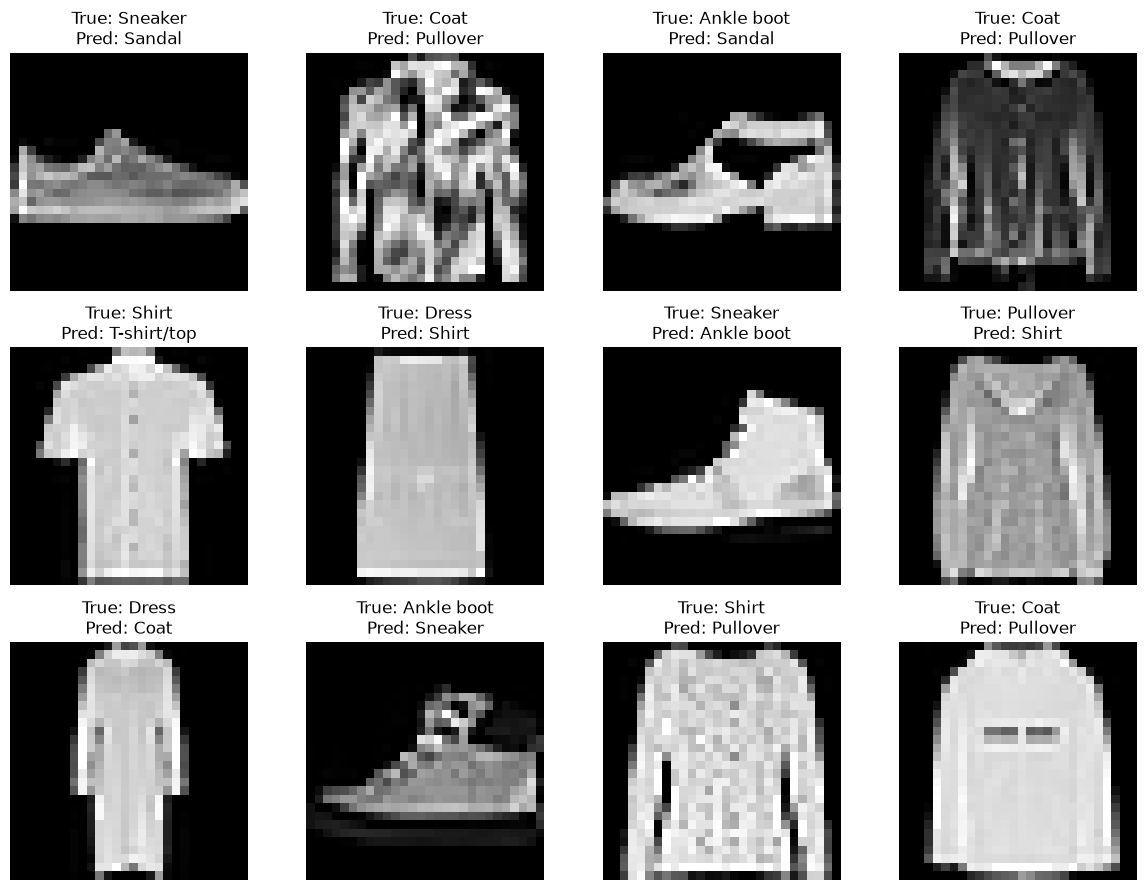

In [9]:
fig, axes = plt.subplots(
    3,
    4,
    figsize=(12, 9)
)

for ax, index in zip(
    axes.flat,
    misclassified_indices[:12]
):

    ax.imshow(
        X_test[index],
        cmap="gray"
    )

    true_name = CLASS_NAMES[
        y_test[index]
    ]

    predicted_name = CLASS_NAMES[
        y_test_pred[index]
    ]

    ax.set_title(
        f"True: {true_name}\n"
        f"Pred: {predicted_name}"
    )

    ax.axis("off")

plt.tight_layout()

plt.savefig(
    "../results/figures/"
    "svm_misclassified_examples.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
PCA_SWEEP = [
    10,
    25,
    50,
    100,
    200
]
pca_sweep_results = []

for components in PCA_SWEEP:

    print(
        f"Testing {components} components..."
    )

    sweep_pca, X_fit_sweep = fit_pca(
        X_fit,
        components
    )

    X_val_sweep = transform_pca(
        sweep_pca,
        X_val
    )

    sweep_model = create_svm(
        C=10,
        gamma="scale"
    )

    sweep_model.fit(
        X_fit_sweep,
        y_fit
    )

    predictions = sweep_model.predict(
        X_val_sweep
    )

    accuracy = accuracy_score(
        y_val,
        predictions
    )

    pca_sweep_results.append({
        "components": components,
        "accuracy": accuracy
    })
    

Testing 10 components...
Testing 25 components...
Testing 50 components...
Testing 100 components...
Testing 200 components...


In [17]:
print(pca_sweep_df.to_string(index=False))

 components  accuracy
         10  0.836417
         25  0.890583
         50  0.900917
        100  0.907583
        200  0.911333


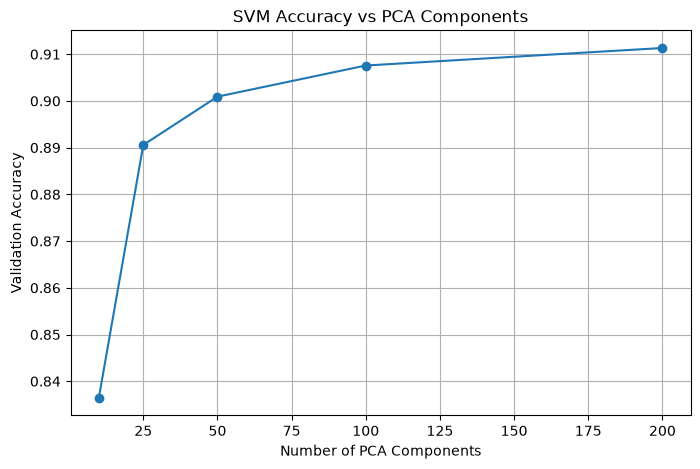

In [11]:
pca_sweep_df = pd.DataFrame(
    pca_sweep_results
)

pca_sweep_df
plt.figure(figsize=(8, 5))

plt.plot(
    pca_sweep_df["components"],
    pca_sweep_df["accuracy"],
    marker="o"
)

plt.xlabel(
    "Number of PCA Components"
)

plt.ylabel(
    "Validation Accuracy"
)

plt.title(
    "SVM Accuracy vs PCA Components"
)

plt.grid(True)

plt.savefig(
    "../results/figures/"
    "pca_components_vs_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
pca_sweep_df.to_csv(
    "../results/pca_sweep.csv",
    index=False
)